# Machine Learning 2026 — Assignment 4
**Roll number:** 2024027 · P2 is handwritten (in the report).

In [1]:
ROLL_NO = 2024027
SEED = ROLL_NO          # used for every random operation

import os
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, floatmode="fixed")
os.makedirs("figures", exist_ok=True)

def check(msg, ok, got=None, exp=None):
    # print PASS, or stop with the value we got and the expected value
    if ok:
        print("PASS ", msg)
    else:
        raise AssertionError(f"FAIL {msg}: got {got}, expected {exp}")

## P1. Activation functions and their derivatives
To avoid overflow, sigmoid and softplus only compute $e^{-|z|}$ (always between 0 and 1).

In [2]:
# (a) activation functions
def sig(z):
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

def tanh(z):  return np.tanh(z)
def relu(z):  return np.maximum(z, 0)
def lrelu(z, a=0.1): return np.where(z > 0, z, a * z)
def splus(z): return np.maximum(z, 0) + np.log1p(np.exp(-np.abs(z)))

# (b) derivatives
def dsig(z):  return sig(z) * (1 - sig(z))
def dtanh(z): return 1 - np.tanh(z) ** 2
def drelu(z): return (z > 0).astype(z.dtype)          # ReLU'(0) = 0
def dlrelu(z, a=0.1): return np.where(z > 0, 1.0, a)
def dsplus(z): return sig(z)

acts = {"sigmoid": (sig, dsig), "tanh": (tanh, dtanh), "relu": (relu, drelu),
        "leaky_relu": (lrelu, dlrelu), "softplus": (splus, dsplus)}

# test: no overflow for |z| up to 1000, output has the same shape as the input
zb = np.array([[-1000.0, -500.0, 0.0], [1.0, 500.0, 1000.0]])
with np.errstate(over="raise"):
    for k, (f, df) in acts.items():
        ok = np.isfinite(f(zb)).all() and np.isfinite(df(zb)).all() and f(zb).shape == zb.shape
        check(k + ": no overflow, same shape", ok, f(zb))

PASS  sigmoid: no overflow, same shape
PASS  tanh: no overflow, same shape
PASS  relu: no overflow, same shape
PASS  leaky_relu: no overflow, same shape
PASS  softplus: no overflow, same shape


In [3]:
# (c) numerical derivative (central difference)
def num_deriv(f, z, eps=1e-6):
    return (f(z + eps) - f(z - eps)) / (2 * eps)

zt = np.array([-3, -1.5, -0.5, 0.5, 1.5, 3])
for k, (f, df) in acts.items():
    err = np.abs(df(zt) - num_deriv(f, zt)).max()
    check(f"{k} derivative, max error = {err:.1e}", err < 1e-6, err, "< 1e-6")

PASS  sigmoid derivative, max error = 4.8e-11
PASS  tanh derivative, max error = 1.2e-11
PASS  relu derivative, max error = 1.4e-10
PASS  leaky_relu derivative, max error = 1.4e-10
PASS  softplus derivative, max error = 8.9e-11


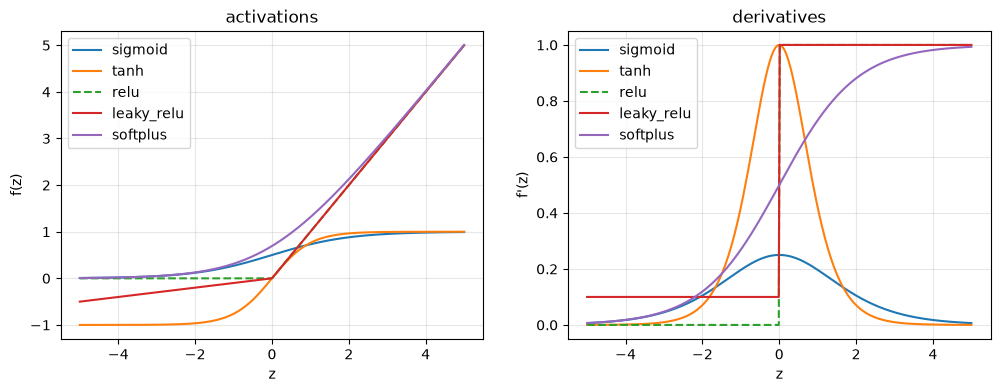

max sigmoid' = 0.2500
max tanh' = 0.9998
max relu' = 1.0000
max leaky_relu' = 1.0000
max softplus' = 0.9933


In [4]:
# (d) plot on 400 points in [-5, 5] and the maximum of each derivative
zg = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (f, df) in acts.items():
    ls = "--" if k == "relu" else "-"        # dashed, so ReLU is visible under leaky ReLU
    ax[0].plot(zg, f(zg), ls, label=k)
    ax[1].plot(zg, df(zg), ls, label=k)
ax[0].set_title("activations"); ax[0].set_ylabel("f(z)")
ax[1].set_title("derivatives"); ax[1].set_ylabel("f'(z)")
for a in ax:
    a.set_xlabel("z"); a.grid(alpha=0.3); a.legend()
plt.savefig("figures/p1_activations.png", dpi=150, bbox_inches="tight")
plt.show()

for k, (f, df) in acts.items():
    print(f"max {k}' = {df(zg).max():.4f}")

In [5]:
# (e) tanh(z) = 2 sig(2z) - 1
d = np.abs(tanh(zg) - (2 * sig(2 * zg) - 1)).max()
check(f"tanh(z) = 2 sig(2z) - 1, max diff = {d:.1e}", d < 1e-12, d, "< 1e-12")

# Checkpoint (i): derivatives at z = -2, 0, 2
zc = np.array([-2.0, 0.0, 2.0])
for k, (f, df) in acts.items():
    print(f"{k:11s}", df(zc))

PASS  tanh(z) = 2 sig(2z) - 1, max diff = 3.3e-16
sigmoid     [0.1050 0.2500 0.1050]
tanh        [0.0707 1.0000 0.0707]
relu        [0.0000 0.0000 1.0000]
leaky_relu  [0.1000 0.1000 1.0000]
softplus    [0.1192 0.5000 0.8808]


## P3. Softmax and cross-entropy
$p_{ij} = e^{Z_{ij}} / \sum_m e^{Z_{im}}$, $\quad L = -\frac{1}{n}\sum_i \ln p_{i,y_i}$, $\quad \partial L/\partial Z = (P - Y)/n$ (Y = one-hot labels)

In [6]:
# (a) softmax: subtract the row max so exp cannot overflow
def smax(Z):
    e = np.exp(Z - Z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

# (b) mean cross-entropy
def ce(P, y):
    n = len(y)
    return float(-np.mean(np.log(P[np.arange(n), y] + 1e-12)))

# (c) gradient w.r.t. Z
def dce(Z, y):
    n = len(y)
    G = smax(Z)
    G[np.arange(n), y] -= 1        # P - Y
    return G / n

rng = np.random.default_rng(SEED)
Z = rng.normal(size=(5, 4))
y = rng.integers(0, 4, size=5)
P = smax(Z)
check("softmax shape (n, k) and rows sum to 1", P.shape == Z.shape and np.allclose(P.sum(1), 1), P.sum(1))
print(f"loss = {ce(P, y):.4f}")

PASS  softmax shape (n, k) and rows sum to 1
loss = 1.9630


In [7]:
# (d) gradient check with central differences, step 1e-6, random 5 x 4 logits
def ngrad(fn, X, eps=1e-6):
    # numerical gradient of fn() w.r.t. every entry of X
    G = np.zeros_like(X)
    for i in np.ndindex(X.shape):
        old = X[i]
        X[i] = old + eps; fp = fn()
        X[i] = old - eps; fm = fn()
        X[i] = old
        G[i] = (fp - fm) / (2 * eps)
    return G

err = np.abs(dce(Z, y) - ngrad(lambda: ce(smax(Z), y), Z)).max()
check(f"gradient check, max error = {err:.1e}", err < 1e-7, err, "< 1e-7")

PASS  gradient check, max error = 1.8e-10


In [8]:
# (e) adding a constant does not change softmax; naive softmax gives nan
d = np.abs(smax(Z + 100) - smax(Z)).max()
check(f"softmax(Z + 100) = softmax(Z), max diff = {d:.1e}", d < 1e-12, d, "< 1e-12")

Zh = np.array([[1000.0, 1001.0, 1002.0]])
with np.errstate(all="ignore"):
    Pn = np.exp(Zh) / np.exp(Zh).sum(axis=1, keepdims=True)     # naive softmax
print("naive :", Pn)
print("stable:", smax(Zh))
check("naive gives nan, ours does not", np.isnan(Pn).any() and np.isfinite(smax(Zh)).all(),
      (Pn, smax(Zh)), "naive nan, stable finite")

PASS  softmax(Z + 100) = softmax(Z), max diff = 1.2e-15
naive : [[nan nan nan]]
stable: [[0.0900 0.2447 0.6652]]
PASS  naive gives nan, ours does not


In [9]:
# Checkpoint: Z = [[2.0, 1.0, 0.1]], y = [1]
Zc, yc = np.array([[2.0, 1.0, 0.1]]), np.array([1])
print("softmax :", smax(Zc))
print(f"loss    : {ce(smax(Zc), yc):.4f}")
print("gradient:", dce(Zc, yc), " row sum =", dce(Zc, yc).sum())
check("checkpoint loss = 1.4170", abs(ce(smax(Zc), yc) - 1.4170) < 1e-4, ce(smax(Zc), yc), 1.4170)

softmax : [[0.6590 0.2424 0.0986]]
loss    : 1.4170
gradient: [[ 0.6590 -0.7576  0.0986]]  row sum = 0.0
PASS  checkpoint loss = 1.4170


## P4. Data pipelines: CIFAR-10 and Wine
`torchvision` and `sklearn` are used **only** to read the data files; everything else is NumPy.

In [10]:
# CIFAR-10 split: 10000 random training images -> 8000 train + 2000 val; test = first 2000 of the test set
from torchvision.datasets import CIFAR10

tr = CIFAR10("data", train=True, download=True)
te = CIFAR10("data", train=False, download=True)
names = tr.classes

idx = np.random.default_rng(SEED).choice(50000, size=10000, replace=False)
img_tr, ytr = tr.data[idx[:8000]], np.array(tr.targets)[idx[:8000]]     # uint8 (N, 32, 32, 3)
img_va, yva = tr.data[idx[8000:]], np.array(tr.targets)[idx[8000:]]
img_te, yte = te.data[:2000], np.array(te.targets)[:2000]
print("raw shapes:", img_tr.shape, img_va.shape, img_te.shape)

raw shapes: (8000, 32, 32, 3) (2000, 32, 32, 3) (2000, 32, 32, 3)


In [11]:
# (a) floats in [0,1] -> per-channel standardise (train stats only) -> flatten channel-first (R, G, B)
def to01(X):                          # (N,32,32,3) uint8 -> (N,3,32,32) float32 in [0,1]
    return (X / 255.0).astype(np.float32).transpose(0, 3, 1, 2)

Xtr4, Xva4, Xte4 = to01(img_tr), to01(img_va), to01(img_te)

mu = Xtr4.mean(axis=(0, 2, 3), dtype=np.float64).astype(np.float32)   # training images only
sd = Xtr4.std(axis=(0, 2, 3), dtype=np.float64).astype(np.float32)

def norm(X):                          # standardise each channel, flatten to (N, 3072)
    X = (X - mu[None, :, None, None]) / sd[None, :, None, None]
    return X.reshape(len(X), -1)

Xtr, Xva, Xte = norm(Xtr4), norm(Xva4), norm(Xte4)
print("Xtr", Xtr.shape, " Xva", Xva.shape, " Xte", Xte.shape, " ytr", ytr.shape, " yva", yva.shape, " yte", yte.shape)
check("shapes (8000/2000/2000, 3072)", Xtr.shape == (8000, 3072) and Xva.shape == Xte.shape == (2000, 3072))
check("flatten order: first 1024 values = red channel",
      np.allclose(Xtr[0, :1024], ((Xtr4[0, 0] - mu[0]) / sd[0]).ravel()))

def cstats(X):                        # mean and std of each colour channel
    X = X.reshape(len(X), 3, -1).astype(np.float64)
    return X.mean(axis=(0, 2)), X.std(axis=(0, 2))

print(f"\n{'set':6s}{'stage':8s}{'mean (R, G, B)':>30s}{'std (R, G, B)':>30s}")
for s, A, B in [("train", Xtr4, Xtr), ("val", Xva4, Xva), ("test", Xte4, Xte)]:
    for stage, X in [("before", A), ("after", B)]:
        m, v = cstats(X)
        print(f"{s:6s}{stage:8s}{str(m.round(4)):>30s}{str(v.round(4)):>30s}")

Xtr (8000, 3072)  Xva (2000, 3072)  Xte (2000, 3072)  ytr (8000,)  yva (2000,)  yte (2000,)
PASS  shapes (8000/2000/2000, 3072)
PASS  flatten order: first 1024 values = red channel

set   stage                   mean (R, G, B)                 std (R, G, B)
train before          [0.4910 0.4816 0.4458]        [0.2473 0.2439 0.2617]


train after        [-0.0000  0.0000 -0.0000]        [1.0000 1.0000 1.0000]
val   before          [0.4901 0.4787 0.4435]        [0.2462 0.2424 0.2595]
val   after        [-0.0038 -0.0116 -0.0088]        [0.9959 0.9938 0.9918]
test  before          [0.4974 0.4887 0.4555]        [0.2471 0.2424 0.2626]
test  after           [0.0257 0.0293 0.0369]        [0.9993 0.9939 1.0034]


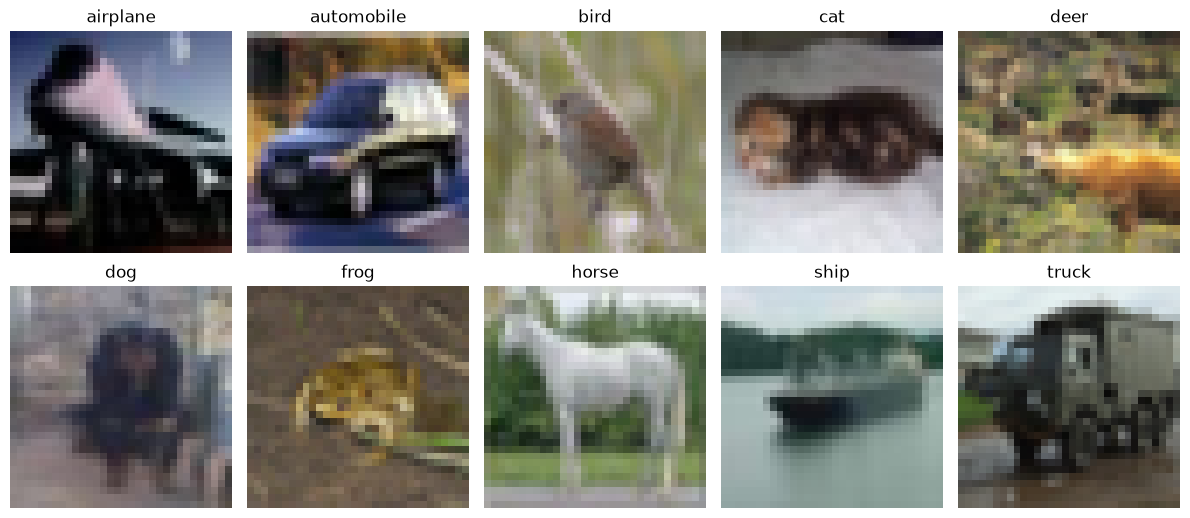

airplane      820
automobile    797
bird          769
cat           822
deer          829
dog           790
frog          802
horse         798
ship          786
truck         787
total        8000


In [12]:
# (b) one example per class + number of training images per class
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for c in range(10):
    a = ax[c // 5, c % 5]
    a.imshow(img_tr[np.where(ytr == c)[0][0]])     # first training image of class c
    a.set_title(names[c]); a.axis("off")
plt.tight_layout()
plt.savefig("figures/p4_classes.png", dpi=150, bbox_inches="tight")
plt.show()

cnt = np.bincount(ytr, minlength=10)
for c in range(10):
    print(f"{names[c]:12s}{cnt[c]:5d}")
print(f"{'total':12s}{cnt.sum():5d}")

In [13]:
# Wine (for P5, P6, P9). The split is not given in the assignment, so we use
# a SEED permutation, 70% train / 15% val / 15% test, standardised with training statistics.
from sklearn.datasets import load_wine

Xw, yw = load_wine(return_X_y=True)
p = np.random.default_rng(SEED).permutation(len(Xw))
a, b = int(0.70 * len(Xw)), int(0.85 * len(Xw))
mw, sw = Xw[p[:a]].mean(axis=0), Xw[p[:a]].std(axis=0)

Xw_tr, yw_tr = (Xw[p[:a]] - mw) / sw, yw[p[:a]]
Xw_va, yw_va = (Xw[p[a:b]] - mw) / sw, yw[p[a:b]]
Xw_te, yw_te = (Xw[p[b:]] - mw) / sw, yw[p[b:]]
print("Wine train", Xw_tr.shape, " val", Xw_va.shape, " test", Xw_te.shape)

Wine train (124, 13)  val (27, 13)  test (27, 13)


## P5. Forward pass through an MLP from scratch (Wine: 13 → 16 → 8 → 3, ReLU)
$Z_l = A_{l-1}W_l + b_l$, $A_l = \phi(Z_l)$ for $l<L$, $A_L = Z_L$. In the code `Ws[0]` is $W_1$, `Zs[0]` is $Z_1$, `As[0]` is $A_0 = X$.

In [14]:
# (a) He initialisation and number of parameters
def init(sz, dt=np.float64):
    rng = np.random.default_rng(SEED)
    Ws = [rng.normal(0, np.sqrt(2 / m), size=(m, n)).astype(dt) for m, n in zip(sz[:-1], sz[1:])]
    bs = [np.zeros(n, dtype=dt) for n in sz[1:]]
    return Ws, bs

sz = [13, 16, 8, 3]
Ws, bs = init(sz)
n_formula = sum(m * n + n for m, n in zip(sz[:-1], sz[1:]))
n_count = sum(W.size for W in Ws) + sum(b.size for b in bs)
print("by formula (13*16+16) + (16*8+8) + (8*3+3) =", n_formula, ";  by counting =", n_count)
check("formula = count = 387", n_formula == n_count == 387, (n_formula, n_count), 387)

by formula (13*16+16) + (16*8+8) + (8*3+3) = 387 ;  by counting = 387
PASS  formula = count = 387


In [15]:
# (b) forward pass that keeps every Z and A; run on the first 5 training samples
def forward(Ws, bs, X, act="relu"):
    f = acts[act][0]
    Zs, As = [], [X]
    for l in range(len(Ws)):
        Z = As[-1] @ Ws[l] + bs[l]
        Zs.append(Z)
        As.append(f(Z) if l < len(Ws) - 1 else Z)    # no activation on the output layer
    return Zs, As

X5 = Xw_tr[:5]
Zs, As = forward(Ws, bs, X5)
print("A0", As[0].shape)
for l in range(len(Zs)):
    print(f"Z{l+1} {Zs[l].shape}   A{l+1} {As[l+1].shape}")

A0 (5, 13)
Z1 (5, 16)   A1 (5, 16)
Z2 (5, 8)   A2 (5, 8)
Z3 (5, 3)   A3 (5, 3)


In [16]:
# (c) loss at initialisation vs ln 3, then with the last weights x 0.01
L0 = ce(smax(forward(Ws, bs, Xw_tr)[0][-1]), yw_tr)
L1 = ce(smax(forward(Ws[:-1] + [Ws[-1] * 0.01], bs, Xw_tr)[0][-1]), yw_tr)
print(f"ln 3 = {np.log(3):.4f},  loss at init = {L0:.4f},  loss with last weights x0.01 = {L1:.4f}")
check("scaled loss is close to ln 3", abs(L1 - np.log(3)) < 0.05, L1, np.log(3))

ln 3 = 1.0986,  loss at init = 2.6385,  loss with last weights x0.01 = 1.1085
PASS  scaled loss is close to ln 3


**(c) Explanation.** At initialisation (2.6385 > ln 3) the He-initialised logits have a large spread, so the softmax is already confident, and where it is confidently wrong $-\ln p$ is large.
With the last weights × 0.01 (1.1085 ≈ ln 3) all logits are almost 0, the softmax gives about 1/3 to every class, and the loss is about $-\ln(1/3) = \ln 3$.

In [17]:
# (d) vectorisation: 5 samples one at a time vs one batch
Zb = forward(Ws, bs, X5)[0][-1]
Zl = np.vstack([forward(Ws, bs, X5[i:i+1])[0][-1] for i in range(5)])
d = np.abs(Zb - Zl).max()
check(f"loop logits = batch logits, max diff = {d:.1e}", d < 1e-12, d, "< 1e-12")

PASS  loop logits = batch logits, max diff = 6.7e-16


In [18]:
# (e) mean and std of the first hidden layer A1 on the training set
for k in ["relu", "tanh", "sigmoid"]:
    A1 = forward(Ws, bs, Xw_tr, act=k)[1][1]
    print(f"{k:8s} mean = {A1.mean():.4f}   std = {A1.std():.4f}")

relu     mean = 0.5881   std = 0.8993
tanh     mean = 0.0005   std = 0.7241
sigmoid  mean = 0.4987   std = 0.2664


## P6. Backward pass from scratch and gradient checking
$J = -\frac{1}{B}\sum_i \ln P_{i,y_i} + \frac{\lambda}{2}\sum_l \|W_l\|_F^2$

$dZ_L = (P-Y)/B$, $\ dW_l = A_{l-1}^\top dZ_l + \lambda W_l$, $\ db_l = \sum_i (dZ_l)_{i,:}$, $\ dA_{l-1} = dZ_l W_l^\top$, $\ dZ_{l-1} = dA_{l-1} \odot \phi'(Z_{l-1})$

In [19]:
# (a) full loss with the L2 penalty
def loss(Ws, bs, X, y, lam=0.0, act="relu"):
    Zs, As = forward(Ws, bs, X, act)
    J = ce(smax(Zs[-1]), y) + lam / 2 * sum((W ** 2).sum() for W in Ws)
    return J, Zs, As

# (b) backward pass; returns dW, db and dZ of every layer. bug = 1, 2, 3 switches on one error (for (c))
def backward(Ws, Zs, As, y, lam=0.0, act="relu", bug=0):
    df = acts[act][1]
    B, L = len(y), len(Ws)
    Y = np.eye(Ws[-1].shape[1], dtype=Zs[-1].dtype)[y]       # one-hot labels
    dZ = smax(Zs[-1]) - Y
    if bug != 1:
        dZ = dZ / B                                          # bug 1: no division by B
    dWs, dbs, dZs = [None] * L, [None] * L, [None] * L
    for l in range(L - 1, -1, -1):                           # last layer first
        dZs[l] = dZ
        A = Zs[l - 1] if (bug == 2 and l > 0) else As[l]     # bug 2: Z instead of A
        dWs[l] = A.T @ dZ + lam * Ws[l]
        dbs[l] = dZ.sum(axis=0)
        if l > 0:
            dA = dZ @ Ws[l].T
            dZ = dA if bug == 3 else dA * df(Zs[l - 1])      # bug 3: no phi'
    return dWs, dbs, dZs

In [20]:
# gradient check: network 13-16-8-3, Wine training set, lambda = 0.01, eps = 1e-5
# (eps = 1e-5, not 1e-6: some gradients are ~1e-6 and with 1e-6 rounding alone gives relative errors ~1e-6)
def gcheck(Ws, bs, X, y, lam, bug=0, eps=1e-5):
    J, Zs, As = loss(Ws, bs, X, y, lam)
    dWs, dbs, _ = backward(Ws, Zs, As, y, lam, bug=bug)
    out = {}
    for l in range(len(Ws)):
        for k, P, G in [("W", Ws[l], dWs[l]), ("b", bs[l], dbs[l])]:
            Gn = ngrad(lambda: loss(Ws, bs, X, y, lam)[0], P, eps)
            rel = np.abs(G - Gn) / np.maximum(1e-8, np.abs(G) + np.abs(Gn))
            out[f"{k}{l+1}"] = rel.max()           # worst relative error of this array
    return out

Wg, bg = init([13, 16, 8, 3])
lam = 0.01
ok = gcheck(Wg, bg, Xw_tr, yw_tr, lam)
worst = max(ok.values())
check(f"correct backward pass, worst relative error = {worst:.1e}", worst < 1e-5, worst, "< 1e-5")

PASS  correct backward pass, worst relative error = 9.0e-07


In [21]:
# (c) bug detection: worst relative error per parameter for each bug
res = {0: ok, 1: gcheck(Wg, bg, Xw_tr, yw_tr, lam, bug=1),
       2: gcheck(Wg, bg, Xw_tr, yw_tr, lam, bug=2), 3: gcheck(Wg, bg, Xw_tr, yw_tr, lam, bug=3)}

print(f"{'param':6s}{'correct':>11s}{'bug 1':>11s}{'bug 2':>11s}{'bug 3':>11s}")
for k in ok:
    print(f"{k:6s}" + "".join(f"{res[b][k]:11.2e}" for b in range(4)))
print(f"{'WORST':6s}" + "".join(f"{max(res[b].values()):11.2e}" for b in range(4)))
for b in [1, 2, 3]:
    check(f"bug {b} detected", max(res[b].values()) > 1e-3, max(res[b].values()), "> 1e-3")

param     correct      bug 1      bug 2      bug 3
W1       8.97e-07   1.00e+00   8.97e-07   1.00e+00
b1       1.15e-07   9.84e-01   1.15e-07   1.00e+00
W2       2.77e-08   1.00e+00   1.00e+00   1.00e+00
b2       3.37e-09   9.84e-01   3.37e-09   1.00e+00
W3       2.84e-09   1.00e+00   1.00e+00   2.84e-09
b3       5.07e-10   9.84e-01   5.07e-10   5.07e-10
WORST    8.97e-07   1.00e+00   1.00e+00   1.00e+00
PASS  bug 1 detected
PASS  bug 2 detected
PASS  bug 3 detected


**(c) Which term is wrong:**

| Bug | Wrong term | What the table shows |
|---|---|---|
| 1 | $dZ_L = (P-Y)/B$ (no $1/B$) | all gradients wrong: the error starts at the output and reaches every layer |
| 2 | $dW_l = A_{l-1}^\top dZ_l$ (uses $Z_{l-1}$) | only W2 and W3 wrong; W1 uses $A_0 = X$ and biases do not use $A$ |
| 3 | $dZ_{l-1} = dA_{l-1} \odot \phi'(Z_{l-1})$ (no $\phi'$) | W3, b3 correct (computed before the first $\phi'$); W1, b1, W2, b2 wrong |

loss 1.2289 -> 0.0095 after 24 steps
PASS  loss < 0.01 within 500 steps


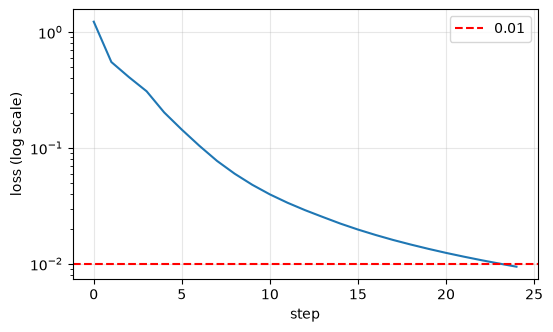

In [22]:
# (d) overfit test: 13-8-3, first 8 training samples, lr 0.5, no penalty, at most 500 steps
def overfit(sz, X, y, lr, tgt, dt=np.float64, steps=500):
    # plain gradient descent until loss < tgt; returns number of steps and the loss history
    Ws, bs = init(sz, dt)
    hist = []
    for t in range(steps + 1):                # t = number of updates done so far
        J, Zs, As = loss(Ws, bs, X, y)
        hist.append(J)
        if J < tgt or t == steps:
            break
        dWs, dbs, _ = backward(Ws, Zs, As, y)
        for l in range(len(Ws)):
            Ws[l] -= lr * dWs[l]
            bs[l] -= lr * dbs[l]
    return t, hist

t, hist = overfit([13, 8, 3], Xw_tr[:8], yw_tr[:8], lr=0.5, tgt=0.01)
print(f"loss {hist[0]:.4f} -> {hist[-1]:.4f} after {t} steps")
check("loss < 0.01 within 500 steps", hist[-1] < 0.01, hist[-1], "< 0.01")

plt.figure(figsize=(6, 3.5))
plt.semilogy(hist)
plt.axhline(0.01, color="r", ls="--", label="0.01")
plt.xlabel("step"); plt.ylabel("loss (log scale)"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/p6_overfit.png", dpi=150, bbox_inches="tight")
plt.show()

## P7. Training an MLP from scratch on CIFAR-10
Network 3072 → 256 → 128 → 10, ReLU, He init, float32. Mini-batches of 128, momentum 0.9: $v \leftarrow \mu v - \eta\, g$, $\ \theta \leftarrow \theta + v$.

In [23]:
# (a) number of parameters and loss at initialisation vs ln 10
sz7 = [3072, 256, 128, 10]
W7, b7 = init(sz7, np.float32)
n7 = sum(m * n + n for m, n in zip(sz7[:-1], sz7[1:]))
check("parameters: formula = count", n7 == sum(W.size for W in W7) + sum(b.size for b in b7), n7)
L0 = ce(smax(forward(W7, b7, Xtr)[0][-1]), ytr)
print(f"parameters = {n7}  (first layer: {W7[0].size + b7[0].size} = {(W7[0].size + b7[0].size) / n7:.2%})")
print(f"loss at init = {L0:.4f},  ln 10 = {np.log(10):.4f}")

PASS  parameters: formula = count


parameters = 820874  (first layer: 786688 = 95.84%)
loss at init = 2.8329,  ln 10 = 2.3026


In [24]:
# (b) overfit test: 64 training images, plain GD, lr 0.05, no penalty, at most 500 steps
t, hist = overfit(sz7, Xtr[:64], ytr[:64], lr=0.05, tgt=0.05, dt=np.float32)
print(f"loss {hist[0]:.4f} -> {hist[-1]:.4f} after {t} steps")
check("loss < 0.05 within 500 steps", hist[-1] < 0.05, hist[-1], "< 0.05")

loss 2.8611 -> 0.0476 after 21 steps
PASS  loss < 0.05 within 500 steps


epoch  1: train loss 1.5722 acc 0.4522 | val loss 1.8263 acc 0.3645


epoch  2: train loss 1.3040 acc 0.5569 | val loss 1.6999 acc 0.4100


epoch  3: train loss 1.1846 acc 0.5962 | val loss 1.7216 acc 0.4220


epoch  4: train loss 1.0543 acc 0.6516 | val loss 1.7800 acc 0.4170


epoch  5: train loss 0.9146 acc 0.6986 | val loss 1.8362 acc 0.4075


epoch  6: train loss 0.8017 acc 0.7419 | val loss 1.8751 acc 0.4180


... (5 outputs left out)

epoch 12: train loss 0.2779 acc 0.9260 | val loss 2.3097 acc 0.4130


epoch 13: train loss 0.2459 acc 0.9347 | val loss 2.4695 acc 0.4280


epoch 14: train loss 0.2313 acc 0.9386 | val loss 2.6006 acc 0.3980


epoch 15: train loss 0.1392 acc 0.9699 | val loss 2.5727 acc 0.4330

best epoch 15: val acc = 0.4330, test acc = 0.4315


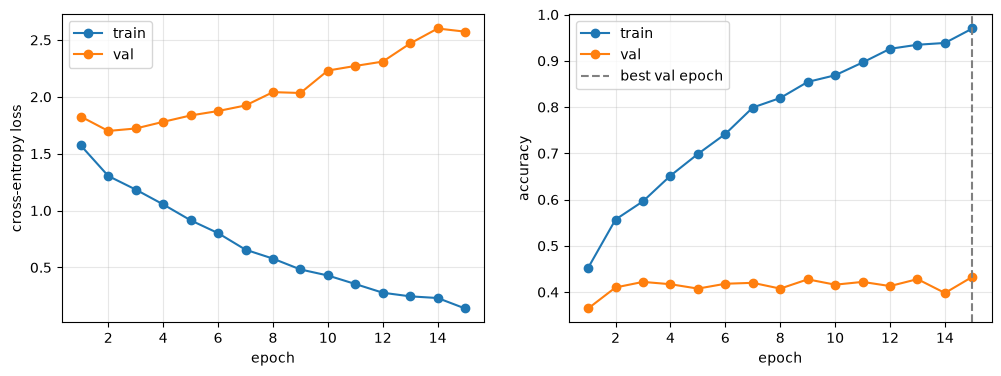

In [25]:
# (c) training with mini-batch SGD + momentum; keep the parameters of the best validation epoch
def evaluate(Ws, bs, X, y):                   # (cross-entropy loss, accuracy)
    Z = forward(Ws, bs, X)[0][-1]
    return ce(smax(Z), y), float((Z.argmax(axis=1) == y).mean())

def train(lam, epochs=15, lr=0.01, mu=0.9, bsz=128):
    Ws, bs = init(sz7, np.float32)
    vW = [np.zeros_like(W) for W in Ws]
    vb = [np.zeros_like(b) for b in bs]
    rng = np.random.default_rng(SEED)
    H = {"tr_loss": [], "tr_acc": [], "va_loss": [], "va_acc": []}
    best = None
    for ep in range(1, epochs + 1):
        p = rng.permutation(len(Xtr))         # new shuffle every epoch
        for i in range(0, len(Xtr), bsz):
            j = p[i:i + bsz]
            J, Zs, As = loss(Ws, bs, Xtr[j], ytr[j], lam)
            dWs, dbs, _ = backward(Ws, Zs, As, ytr[j], lam)
            for l in range(len(Ws)):
                vW[l] = mu * vW[l] - lr * dWs[l]; Ws[l] += vW[l]
                vb[l] = mu * vb[l] - lr * dbs[l]; bs[l] += vb[l]
        trl, tra = evaluate(Ws, bs, Xtr, ytr)
        val, vaa = evaluate(Ws, bs, Xva, yva)
        for k, v in zip(H, [trl, tra, val, vaa]):
            H[k].append(v)
        print(f"epoch {ep:2d}: train loss {trl:.4f} acc {tra:.4f} | val loss {val:.4f} acc {vaa:.4f}")
        if best is None or vaa > best["va_acc"]:
            best = {"ep": ep, "tr_acc": tra, "va_acc": vaa, "Ws": [W.copy() for W in Ws], "bs": [b.copy() for b in bs]}
    return best, H

best, H = train(lam=0.0)
te_acc = evaluate(best["Ws"], best["bs"], Xte, yte)[1]
print(f"\nbest epoch {best['ep']}: val acc = {best['va_acc']:.4f}, test acc = {te_acc:.4f}")

ep = np.arange(1, 16)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, H["tr_loss"], "o-", label="train"); ax[0].plot(ep, H["va_loss"], "o-", label="val")
ax[1].plot(ep, H["tr_acc"], "o-", label="train"); ax[1].plot(ep, H["va_acc"], "o-", label="val")
ax[1].axvline(best["ep"], color="gray", ls="--", label="best val epoch")
ax[0].set_ylabel("cross-entropy loss"); ax[1].set_ylabel("accuracy")
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
plt.savefig("figures/p7_curves.png", dpi=150, bbox_inches="tight")
plt.show()

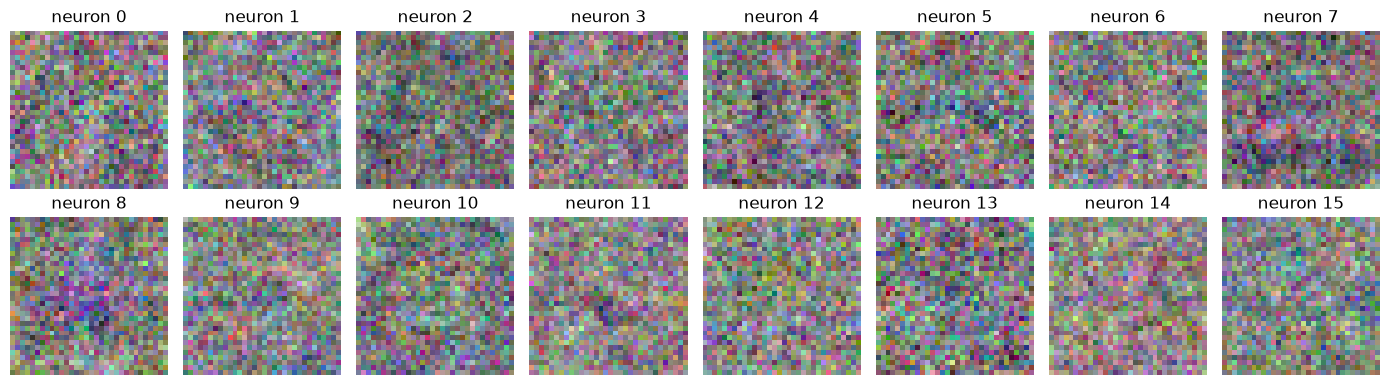

In [26]:
# (d) weights of 16 first-layer neurons as 3 x 32 x 32 colour images, each rescaled to [0, 1]
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for j in range(16):
    w = best["Ws"][0][:, j].reshape(3, 32, 32).transpose(1, 2, 0)   # (3072,) -> (32, 32, 3)
    w = (w - w.min()) / (w.max() - w.min())
    a = ax[j // 8, j % 8]
    a.imshow(w); a.set_title(f"neuron {j}"); a.axis("off")
plt.tight_layout()
plt.savefig("figures/p7_weights.png", dpi=150, bbox_inches="tight")
plt.show()

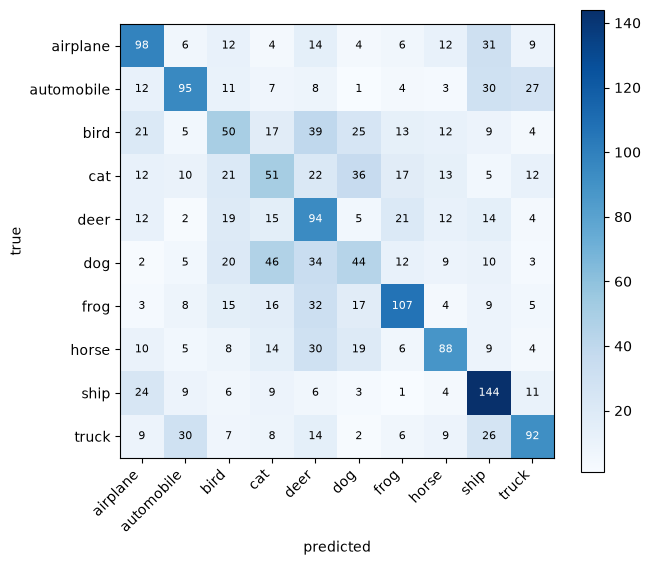

airplane    0.5000
automobile  0.4798
bird        0.2564
cat         0.2563
deer        0.4747
dog         0.2378
frog        0.4954
horse       0.4560
ship        0.6636
truck       0.4532
best class: ship (0.6636),  worst class: dog (0.2378)
PASS  confusion matrix sums to 2000 and matches test accuracy


In [27]:
# (e) confusion matrix on the test set and accuracy of each class
pred = forward(best["Ws"], best["bs"], Xte)[0][-1].argmax(axis=1)
C = np.zeros((10, 10), dtype=int)
np.add.at(C, (yte, pred), 1)                  # rows = true class, columns = predicted class
cacc = C.diagonal() / C.sum(axis=1)

plt.figure(figsize=(7, 6))
plt.imshow(C, cmap="Blues")
for i in range(10):
    for j in range(10):
        plt.text(j, i, C[i, j], ha="center", va="center", fontsize=8,
                 color="white" if C[i, j] > C.max() / 2 else "black")
plt.xticks(range(10), names, rotation=45, ha="right"); plt.yticks(range(10), names)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar()
plt.savefig("figures/p7_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

for c in range(10):
    print(f"{names[c]:12s}{cacc[c]:.4f}")
print(f"best class: {names[cacc.argmax()]} ({cacc.max():.4f}),  worst class: {names[cacc.argmin()]} ({cacc.min():.4f})")
check("confusion matrix sums to 2000 and matches test accuracy",
      C.sum() == 2000 and abs(C.trace() / 2000 - te_acc) < 1e-12, (C.sum(), C.trace() / 2000), (2000, te_acc))

**(e)** Best class: **ship** (0.6636). Ships usually sit on a large blue sea/sky background, and an MLP on raw pixels mostly uses such global colour layouts.
Worst class: **dog** (0.2378). Dogs are confused mostly with **cat** (46 of the 185 test dogs), and also with deer and bird: these animals have similar fur colours, shapes and backgrounds, and the differences are local shape details that an MLP on flattened pixels cannot capture.

epoch  1: train loss 1.5929 acc 0.4390 | val loss 1.8374 acc 0.3485


epoch  2: train loss 1.3183 acc 0.5454 | val loss 1.7036 acc 0.4145


epoch  3: train loss 1.1652 acc 0.6058 | val loss 1.6930 acc 0.4200


epoch  4: train loss 1.0640 acc 0.6518 | val loss 1.7470 acc 0.4235


epoch  5: train loss 0.9025 acc 0.7076 | val loss 1.7779 acc 0.4090


epoch  6: train loss 0.8225 acc 0.7321 | val loss 1.8202 acc 0.4195


... (5 outputs left out)

epoch 12: train loss 0.3195 acc 0.9207 | val loss 2.1829 acc 0.4100


epoch 13: train loss 0.2609 acc 0.9379 | val loss 2.2844 acc 0.4240


epoch 14: train loss 0.2535 acc 0.9346 | val loss 2.4508 acc 0.3965


epoch 15: train loss 0.1579 acc 0.9692 | val loss 2.3782 acc 0.4340

lambda   best ep  train acc  val acc     gap  gap (ep 15)
0             15     0.9699   0.4330  0.5369       0.5369
0.001          7     0.7874   0.4340  0.3534       0.5353


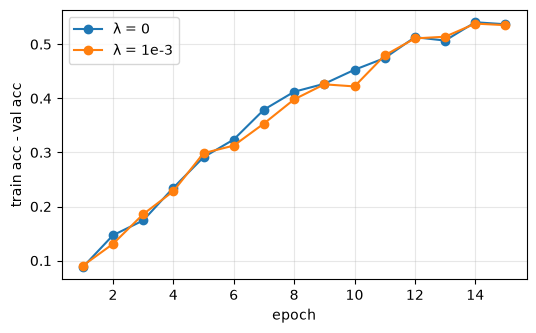

In [28]:
# (f) train again with lambda = 1e-3 and compare the train - val gap
best2, H2 = train(lam=1e-3)

print(f"\n{'lambda':8s}{'best ep':>8s}{'train acc':>11s}{'val acc':>9s}{'gap':>8s}{'gap (ep 15)':>13s}")
for lam_, b_, H_ in [(0.0, best, H), (1e-3, best2, H2)]:
    print(f"{lam_:<8g}{b_['ep']:8d}{b_['tr_acc']:11.4f}{b_['va_acc']:9.4f}{b_['tr_acc'] - b_['va_acc']:8.4f}"
          f"{H_['tr_acc'][-1] - H_['va_acc'][-1]:13.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(ep, np.array(H["tr_acc"]) - H["va_acc"], "o-", label="λ = 0")
plt.plot(ep, np.array(H2["tr_acc"]) - H2["va_acc"], "o-", label="λ = 1e-3")
plt.xlabel("epoch"); plt.ylabel("train acc - val acc"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/p7_gap.png", dpi=150, bbox_inches="tight")
plt.show()

**(f)** With $\lambda = 0$ the gap is very large (train 0.9699 vs val 0.4330 → **0.5369**): the network memorises the training set.
With $\lambda = 10^{-3}$ the gap at the last epoch is almost the same (**0.5353**), and the validation loss is only a little lower (2.3782 vs 2.5727).
Its best validation epoch is earlier (epoch 7, gap 0.3534), so the gap at the selected parameters is smaller, but $\lambda = 10^{-3}$ is too weak to stop 820k parameters from overfitting 8000 images.

## P8. Gradient flow in a deep PyTorch network on CIFAR-10
10 hidden layers of width 128 (11 linear layers), input 3072, 10 logits. One batch = the first 256 images of the P4 training set.

In [29]:
# (a) build the nets: activation in {sigmoid, relu} x init in {xavier, he}, biases zero
import torch
import torch.nn as nn
import torch.nn.functional as F

Xb = torch.tensor(Xtr[:256])                  # (256, 3072) float32
yb = torch.tensor(ytr[:256])                  # (256,) int64

def net(act, ini, bn=False):
    torch.manual_seed(SEED)
    layers, n = [], 3072
    for _ in range(10):                       # 10 hidden layers
        layers.append(nn.Linear(n, 128))
        if bn:
            layers.append(nn.BatchNorm1d(128))
        layers.append(nn.Sigmoid() if act == "sigmoid" else nn.ReLU())
        n = 128
    layers.append(nn.Linear(128, 10))         # output layer
    m = nn.Sequential(*layers)
    for l in lins(m):
        if ini == "xavier":
            nn.init.xavier_normal_(l.weight)
        else:
            nn.init.kaiming_normal_(l.weight, nonlinearity="relu")   # He normal
        nn.init.zeros_(l.bias)
    return m

def lins(m):                                  # the linear layers of a net
    return [l for l in m if isinstance(l, nn.Linear)]

nets = {(a, i): net(a, i) for a in ["sigmoid", "relu"] for i in ["xavier", "he"]}
check("11 linear layers in each net", all(len(lins(m)) == 11 for m in nets.values()))

PASS  11 linear layers in each net


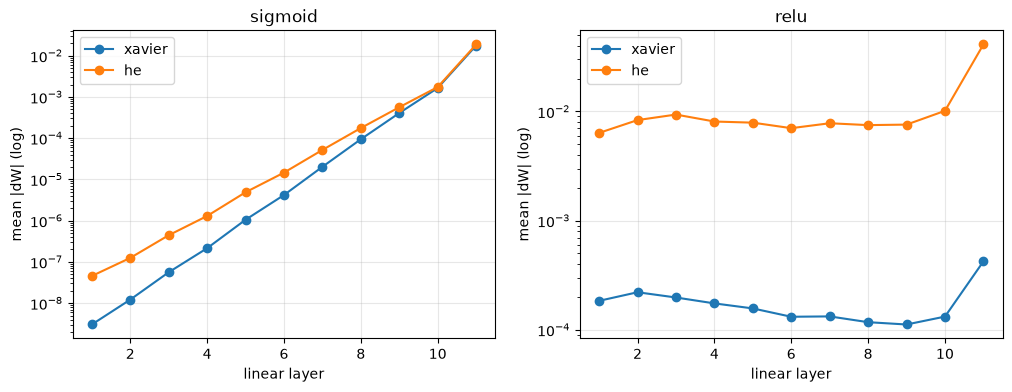

net                 layer 1 grad  layer 11 grad
sigmoid + xavier       3.035e-09      1.760e-02
sigmoid + he           4.552e-08      1.867e-02
relu + xavier          1.842e-04      4.231e-04
relu + he              6.361e-03      4.106e-02


In [30]:
# (b) one forward + backward pass; mean |gradient| of the weight of every linear layer
def grads(m):
    m.zero_grad()
    F.cross_entropy(m(Xb), yb).backward()
    return np.array([l.weight.grad.abs().mean().item() for l in lins(m)])

G = {k: grads(m) for k, m in nets.items()}
li = np.arange(1, 12)                         # layer index 1..11

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j, a in enumerate(["sigmoid", "relu"]):
    for i in ["xavier", "he"]:
        ax[j].semilogy(li, G[(a, i)], "o-", label=i)
    ax[j].set_title(a); ax[j].set_xlabel("linear layer"); ax[j].set_ylabel("mean |dW| (log)")
    ax[j].grid(alpha=0.3); ax[j].legend()
plt.savefig("figures/p8_grads.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"{'net':18s}{'layer 1 grad':>14s}{'layer 11 grad':>15s}")
for (a, i), g in G.items():
    print(f"{a + ' + ' + i:18s}{g[0]:14.3e}{g[-1]:15.3e}")

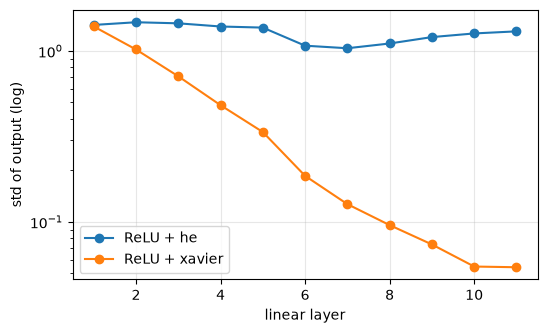

ReLU + he      [1.4185 1.4709 1.4497 1.3890 1.3686 1.0726 1.0364 1.1049 1.2044 1.2650
 1.3011]
ReLU + xavier  [1.3898 1.0191 0.7102 0.4812 0.3352 0.1858 0.1269 0.0957 0.0738 0.0548
 0.0543]


In [31]:
# (c) forward hooks: std of the output of every linear layer, ReLU + He vs ReLU + Xavier
def stds(m):
    out = []
    hs = [l.register_forward_hook(lambda mod, inp, o: out.append(o.std().item())) for l in lins(m)]
    with torch.no_grad():
        m(Xb)
    for h in hs:
        h.remove()
    return np.array(out)

S = {i: stds(nets[("relu", i)]) for i in ["he", "xavier"]}

plt.figure(figsize=(6, 3.5))
for i in ["he", "xavier"]:
    plt.semilogy(li, S[i], "o-", label="ReLU + " + i)
plt.xlabel("linear layer"); plt.ylabel("std of output (log)"); plt.grid(alpha=0.3); plt.legend()
plt.savefig("figures/p8_stds.png", dpi=150, bbox_inches="tight")
plt.show()

for i in ["he", "xavier"]:
    print(f"ReLU + {i:7s}", S[i].round(4))

first-layer mean |dW|: without BN = 3.035e-09,  with BN = 1.466e-03,  ratio = 4.8e+05x


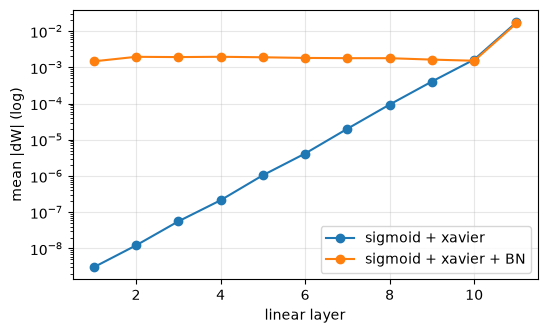

In [32]:
# (d) sigmoid + Xavier with a batch-norm layer after every hidden linear layer
G_bn = grads(net("sigmoid", "xavier", bn=True))
g0, g1 = G[("sigmoid", "xavier")][0], G_bn[0]
print(f"first-layer mean |dW|: without BN = {g0:.3e},  with BN = {g1:.3e},  ratio = {g1 / g0:.1e}x")

plt.figure(figsize=(6, 3.5))
plt.semilogy(li, G[("sigmoid", "xavier")], "o-", label="sigmoid + xavier")
plt.semilogy(li, G_bn, "o-", label="sigmoid + xavier + BN")
plt.xlabel("linear layer"); plt.ylabel("mean |dW| (log)"); plt.grid(alpha=0.3); plt.legend()
plt.savefig("figures/p8_bn.png", dpi=150, bbox_inches="tight")
plt.show()

## P9 (Bonus). Autograd in PyTorch vs hand-written backpropagation
Network 13 → 5 → 4 → 3 (He init, same seed), first 8 Wine training samples, ReLU, $\lambda = 0.01$, float64.

In [33]:
# setup: NumPy reference from P6, and the same parameters as float64 tensors with requires_grad
W9, b9 = init([13, 5, 4, 3])
X9, y9, lam9 = Xw_tr[:8], yw_tr[:8], 0.01
J9, Zs9, As9 = loss(W9, b9, X9, y9, lam9)
dW9, db9, dZ9 = backward(W9, Zs9, As9, y9, lam9)

Wt = [torch.tensor(W, requires_grad=True) for W in W9]       # float64
bt = [torch.tensor(b, requires_grad=True) for b in b9]
Xt, yt = torch.tensor(X9), torch.tensor(y9)

def tloss(detach1=False):
    # only matmul, +, relu, library cross-entropy (logits + integer labels) and the explicit L2 penalty
    A, Zt = Xt, []
    for l in range(3):
        Z = A @ Wt[l] + bt[l]
        Zt.append(Z)
        A = torch.relu(Z) if l < 2 else Z
        if detach1 and l == 0:
            A = A.detach()                     # used in (e)
    J = F.cross_entropy(Zt[-1], yt) + lam9 / 2 * sum((W ** 2).sum() for W in Wt)
    return J, Zt

In [34]:
# (a) PyTorch loss + backward vs the P6 backward pass
J, Zt = tloss()
for Z in Zt:
    Z.retain_grad()                            # keep dL/dZ for (b)
J.backward()

print(f"loss: torch = {J.item():.10f},  numpy = {J9:.10f}")
d = max([np.abs(Wt[l].grad.numpy() - dW9[l]).max() for l in range(3)] +
        [np.abs(bt[l].grad.numpy() - db9[l]).max() for l in range(3)])
check(f"autograd = P6 gradients for all W and b, max diff = {d:.1e}", d < 1e-9, d, "< 1e-9")

loss: torch = 0.9729251425,  numpy = 0.9729251425
PASS  autograd = P6 gradients for all W and b, max diff = 5.7e-17


In [35]:
# (b) gradient of every pre-activation Z_l vs dZ_l from P6
for l in range(3):
    d = np.abs(Zt[l].grad.numpy() - dZ9[l]).max()
    check(f"dZ{l+1}: max diff = {d:.1e}", d < 1e-9, d, "< 1e-9")

PASS  dZ1: max diff = 1.7e-17
PASS  dZ2: max diff = 1.4e-17
PASS  dZ3: max diff = 1.4e-17


In [36]:
# (c) chain of backward nodes reachable from the loss (following grad_fn.next_functions)
pname = {id(p): n for n, p in zip(["W1", "W2", "W3", "b1", "b2", "b3"], Wt + bt)}
seen = set()

def walk(fn, d=0):
    if fn is None or fn in seen:
        return
    seen.add(fn)
    s = type(fn).__name__
    if s == "AccumulateGrad":
        s += f" ({pname[id(fn.variable)]})"
    print("  " * d + s)
    for nxt, _ in fn.next_functions:
        walk(nxt, d + 1)

J, _ = tloss()
walk(J.grad_fn)

ops = {"AddBackward0":        "+  (bias add, loss + penalty, adding the penalty terms)",
       "NllLossBackward0":    "F.cross_entropy: mean negative log-likelihood",
       "LogSoftmaxBackward0": "F.cross_entropy: log-softmax of the logits",
       "MmBackward0":         "A @ W (matrix multiplication)",
       "ReluBackward0":       "torch.relu",
       "MulBackward0":        "lam / 2 * (...)",
       "SumBackward0":        "(W ** 2).sum()",
       "PowBackward0":        "W ** 2",
       "AccumulateGrad":      "leaf parameter: adds the gradient into .grad"}
print("\nnode type -> forward operation")
for s in sorted({type(f).__name__ for f in seen}):
    print(f"  {s:20s} {ops[s]}")

AddBackward0
  NllLossBackward0
    LogSoftmaxBackward0
      AddBackward0
        MmBackward0
          ReluBackward0
            AddBackward0
              MmBackward0
                ReluBackward0
                  AddBackward0
                    MmBackward0
                      AccumulateGrad (W1)
                    AccumulateGrad (b1)
                AccumulateGrad (W2)
              AccumulateGrad (b2)
          AccumulateGrad (W3)
        AccumulateGrad (b3)
  MulBackward0
    AddBackward0
      AddBackward0
        AddBackward0
          SumBackward0
            PowBackward0
        SumBackward0
          PowBackward0
      SumBackward0
        PowBackward0

node type -> forward operation
  AccumulateGrad       leaf parameter: adds the gradient into .grad
  AddBackward0         +  (bias add, loss + penalty, adding the penalty terms)
  LogSoftmaxBackward0  F.cross_entropy: log-softmax of the logits
  MmBackward0          A @ W (matrix multiplication)
  MulBackward0         la

In [37]:
# (d) backward twice on the same graph -> gradients double; then reset them
for p in Wt + bt:
    p.grad = None
J, _ = tloss()
J.backward(retain_graph=True)                  # keep the graph for a second backward
g1 = [p.grad.clone() for p in Wt + bt]
J.backward()
check("second backward doubles every gradient",
      all(torch.allclose(p.grad, 2 * g) for p, g in zip(Wt + bt, g1)))

for p in Wt + bt:
    p.grad.zero_()                             # reset (or p.grad = None, or optimizer.zero_grad())
check("gradients reset to zero", all((p.grad == 0).all() for p in Wt + bt))

PASS  second backward doubles every gradient
PASS  gradients reset to zero


In [38]:
# (e) two ways to stop gradient tracking
# 1) no-gradient context: no graph is built
with torch.no_grad():
    Jn, _ = tloss()
print(f"no_grad: loss = {Jn.item():.4f}, requires_grad = {Jn.requires_grad}, grad_fn = {Jn.grad_fn}")
check("no graph inside torch.no_grad()", not Jn.requires_grad and Jn.grad_fn is None)

# 2) detach the first hidden activation A1
for p in Wt + bt:
    p.grad = None
Jd, _ = tloss(detach1=True)
Jd.backward()
print("W1.grad =\n", Wt[0].grad.numpy())
print("b1.grad =", bt[0].grad)
check("with A1 detached, W1.grad = lam * W1 (penalty only), b1.grad = None",
      torch.allclose(Wt[0].grad, lam9 * Wt[0].detach()) and bt[0].grad is None)

no_grad: loss = 0.9729, requires_grad = False, grad_fn = None
PASS  no graph inside torch.no_grad()
W1.grad =
 [[ 0.0021 -0.0044 -0.0027  0.0098 -0.0033]
 [-0.0022  0.0035  0.0013  0.0007  0.0064]
 [ 0.0025  0.0033 -0.0046 -0.0032  0.0050]
 [-0.0015 -0.0010 -0.0036  0.0021 -0.0021]
 [-0.0031 -0.0024  0.0062 -0.0033  0.0023]
 [-0.0012  0.0032 -0.0038  0.0055  0.0065]
 [-0.0011  0.0036  0.0015  0.0041  0.0013]
 [-0.0008 -0.0009 -0.0020 -0.0023 -0.0000]
 [-0.0033  0.0042 -0.0022 -0.0025  0.0000]
 [-0.0004 -0.0037 -0.0016  0.0038  0.0080]
 [-0.0021 -0.0030 -0.0025 -0.0011  0.0055]
 [-0.0039 -0.0001 -0.0015 -0.0080  0.0014]
 [-0.0101 -0.0012  0.0025  0.0042 -0.0012]]
b1.grad = None
PASS  with A1 detached, W1.grad = lam * W1 (penalty only), b1.grad = None


**(e)** After detaching $A_1$ no gradient from the data loss reaches layer 1. W1 still gets $\lambda W_1$ because the L2 penalty uses W1 directly; b1 is not in the penalty, so `b1.grad` stays `None`.